In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uncertainties

In [50]:
df = pd.read_csv("run_165K.csv")
df.head()

,V_Copper,V_Sapphire,time,sensor_temperature,temperature_setpoint,iTC_P_param,iTC_I_param,iTC_D_param
0,-0.000009,0.000006,0.000000,165.0086,165.0,2.0,1.0,0.0
1,-0.000009,0.000006,0.235002,165.0089,165.0,2.0,1.0,0.0
2,-0.000009,0.000006,0.482557,165.0089,165.0,2.0,1.0,0.0
3,-0.000009,0.000006,0.824296,165.0089,165.0,2.0,1.0,0.0
4,-0.000009,0.000006,1.045137,165.0089,165.0,2.0,1.0,0.0


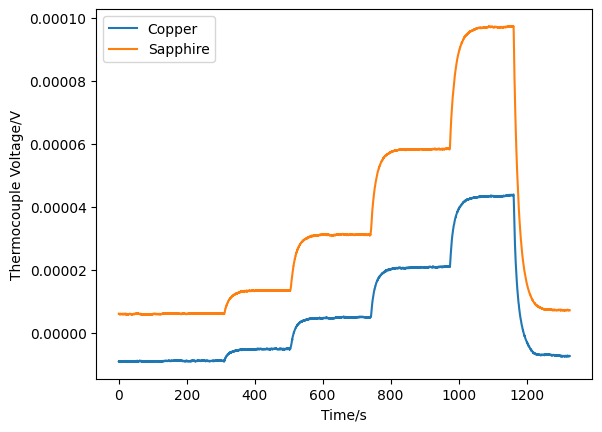

In [51]:
time = df['time']
v_cop = df['V_Copper']
v_sap = df['V_Sapphire']

plt.plot(time, v_cop, label = 'Copper')
plt.plot(time, v_sap, label = 'Sapphire')
plt.legend()
plt.xlabel("Time/s")
plt.ylabel("Thermocouple Voltage/V")
plt.show()

In [52]:
windows15K = {
    "V_Copper":   [(0, 118), (155, 228), (260, 395), (440, 612), (660, 770)],
    "V_Sapphire": [(0, 118), (145, 228), (255, 395), (425, 612), (660, 770)],
}

windows20K = {
    "V_Copper":   [(0, 105), (175, 238), (285, 365), (420, 498), (630, 670)],
    "V_Sapphire": [(0, 105), (140, 238), (270, 365), (390, 498), (620, 670)],
}

windows30K = {
    "V_Copper":   [(0, 115), (200, 292), (340, 430), (500, 670), (725, 855)],
    "V_Sapphire": [(0, 115), (190, 292), (330, 430), (500, 670), (725, 855)],
}

windows40K = {
    "V_Copper":   [(0, 110), (175, 262), (320, 415), (520, 715), (800, 970)],
    "V_Sapphire": [(0, 110), (170, 255), (300, 450), (510, 715), (860, 970)],
}

windows25K = {
    "V_Copper":   [(0, 115), (225, 325), (450, 548), (600, 745), (800, 915)],
    "V_Sapphire": [(0, 115), (215, 330), (375, 550), (600, 745), (800, 915)],
}

windows60K = {
    "V_Copper":   [(0, 120), (180, 345), (400, 615), (700, 955), (1050, 1295), (1340, 1610)],
    "V_Sapphire": [(0, 120), (180, 345), (400, 615), (700, 955), (1050, 1295), (1340, 1610)],
}

windows80K = {
    "V_Copper":   [(0, 215), (300, 635), (700, 1060), (1120, 1400), (1460, 1790), (1870, 2225)],
    "V_Sapphire": [(0, 215), (260, 635), (680, 1060), (1110, 1400), (1460, 1790), (1900, 2090)],
}

windows120K = {
    "V_Copper":   [(25, 280), (350, 590), (650, 825), (900, 1090), (1170, 1315), (1420, 1705)],
    "V_Sapphire": [(25, 280), (350, 590), (650, 825), (900, 1090), (1170, 1315), (1450, 1705)],
}

windows165K = {
    "V_Copper":   [(0, 300), (375, 495), (600, 730), (820, 965), (1060, 1150), (1240, 1325)],
    "V_Sapphire": [(0, 300), (390, 495), (600, 730), (830, 965), (1070, 1150), (1260, 1325)],
}

windows = windows165K

v_avg = {}
v_std = {}

for material, times in windows.items():
    print(material)
    v_avg[material] = []
    v_std[material] = []
    for start, end in times:
        in_window = (time >= start) & (time <= end)
        average = df.loc[in_window, material].mean()
        std = df.loc[in_window, material].std()
        v_avg[material].append(average)
        v_std[material].append(std)
        print(f"  {start}-{end} s: {average:.4e} +- {std:.4e} V")

V_Copper
  0-300 s: -8.9555e-06 +- 1.0648e-07 V
  375-495 s: -5.1660e-06 +- 9.3367e-08 V
  600-730 s: 4.8816e-06 +- 1.4021e-07 V
  820-965 s: 2.0783e-05 +- 1.5022e-07 V
  1060-1150 s: 4.3356e-05 +- 1.2226e-07 V
  1240-1325 s: -7.1500e-06 +- 1.7545e-07 V
V_Sapphire
  0-300 s: 6.0389e-06 +- 1.0142e-07 V
  390-495 s: 1.3424e-05 +- 6.1647e-08 V
  600-730 s: 3.1142e-05 +- 9.4705e-08 V
  830-965 s: 5.8258e-05 +- 9.2343e-08 V
  1070-1150 s: 9.7054e-05 +- 1.0039e-07 V
  1260-1325 s: 7.2747e-06 +- 8.1654e-08 V


In [53]:
baseline = {
    "V_Copper": v_avg["V_Copper"][0],
    "V_Sapphire": v_avg["V_Sapphire"][0]
}

v_avg_adj = {}

for material in v_avg.keys():
    v_avg_adj[material] = []
    #print(material)
    for i in range(1, len(v_avg[material])-1):
        v_avg_adj[material].append(v_avg[material][i]-baseline[material])
for material, values in v_avg_adj.items():
    print(material)
    output = "[0,"
    std_output = f"[{v_std[material][0]},"
    for i, v in enumerate(values, start=1):
        #print(f"  Step {i}: {v:.4e} V")
        output = output + f"{v}"
        std_output = std_output + f"{v_std[material][i-1]}"
        if i != len(values):
            output = output+","
            std_output = std_output+","
    output = output + "]"
    std_output = std_output + "]"
    print(output)
    print(std_output)



V_Copper
[0,3.789484736165005e-06,1.3837124675323755e-05,2.9738481729861167e-05,5.231194403750133e-05]
[1.0647872451681394e-07,1.0647872451681394e-07,9.336698859735027e-08,1.4021159531983268e-07,1.5022332018649506e-07]
V_Sapphire
[0,7.384675303248895e-06,2.5102833868473563e-05,5.221877041202629e-05,9.101473885217247e-05]
[1.0141768580498136e-07,1.0141768580498136e-07,6.164683203492351e-08,9.470522462364442e-08,9.234344236611407e-08]


In [54]:
# --- Baseline-drift correction: straight line between the two baselines ---
v_avg_drift = {}

for material, times in windows.items():
    # midpoint times of every window
    t_mid = [(start + end) / 2 for start, end in times]

    # straight line through (t_first, V_first) and (t_last, V_last)
    t0, t1 = t_mid[0], t_mid[-1]
    v0, v1 = v_avg[material][0], v_avg[material][-1]
    gradient = (v1 - v0) / (t1 - t0)

    def baseline_line(t):
        return v0 + gradient * (t - t0)

    # subtract the line's value at each intermediate step's midpoint
    v_avg_drift[material] = [0]
    for i in range(1, len(times) - 1):
        v_avg_drift[material].append(float(v_avg[material][i] - baseline_line(t_mid[i])))

for material, values in v_avg_drift.items():
    print(material)
    output = "[" + ",".join(f"{v}" for v in values) + "]"
    std_output = "[" + ",".join(f"{v_std[material][i]}" for i in range(len(values))) + "]"
    print(output)
    print(std_output)

V_Copper
[0,3.335108217682181e-06,1.3016058334907423e-05,2.8554711326445386e-05,5.078938412469046e-05]
[1.0647872451681394e-07,9.336698859735027e-08,1.4021159531983268e-07,1.5022332018649506e-07,1.2225681581196777e-07]
V_Sapphire
[0,7.068286428620622e-06,2.454577311485455e-05,5.141022106575403e-05,8.997633434057199e-05]
[1.0141768580498136e-07,6.164683203492351e-08,9.470522462364442e-08,9.234344236611407e-08,1.003905053915975e-07]
